# Conveyor Belt Stoppage Risk

## 1. Business question / Бизнес-задача
Educational construction analytics demonstration. All data are synthetic; AI assisted implementation.
Учебный проект на синтетических данных с помощью AI. Результаты не подтверждают эффективность на реальном оборудовании или стройке.

This notebook shows the complete workflow directly, including the generator, Pandas exploration, preprocessing, training, baseline comparison and evaluation. No import from `project.py` is needed.


## 2. Imports / Библиотеки
Pandas handles tabular data; NumPy generates examples; scikit-learn trains and evaluates models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, r2_score, average_precision_score,
    roc_auc_score, brier_score_loss, precision_score, recall_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

## 3. Reproducible synthetic data / Синтетические данные
The outcome mechanism below is an educational assumption, not an engineering law. Missing predictors are added deliberately.

In [2]:
CONFIG = {'slug': '03_conveyor_failure_prediction', 'title': 'Conveyor Belt Stoppage Risk', 'kind': 'classification', 'target': 'unplanned_stop_next_24h', 'group': 'conveyor_id', 'seed': 73, 'features': {'vibration_mm_s': 'Prior-hour drive vibration, mm/s', 'bearing_temperature_c': 'Prior-hour bearing temperature, Celsius', 'motor_current_a': 'Prior-hour motor current, amperes', 'belt_speed_m_s': 'Prior-hour belt speed, m/s', 'throughput_tph': 'Prior-hour transported mass, tonnes/hour', 'hours_since_maintenance': 'Operating hours since maintenance'}}
FEATURES = list(CONFIG["features"])
TARGET = CONFIG["target"]
GROUP = CONFIG["group"]

def generate_data(seed=CONFIG['seed']):
    """One independent snapshot per fictional conveyor, not a real sensor history.

    The logistic coefficients are illustrative assumptions, not engineering limits.
    All measurements precede the next-24-hour label window.
    """
    rng = np.random.default_rng(seed)
    n = 1920
    vibration = rng.uniform(1, 12, n)
    temp = rng.uniform(40, 105, n)
    throughput = rng.uniform(150, 1600, n)
    speed = rng.uniform(1.0, 4.0, n)
    current = np.clip(40 + 0.065 * throughput + rng.normal(0, 15, n), 20, 190)
    hours = rng.uniform(10, 1400, n)
    logit = -5.6 + 0.3 * vibration + 0.04 * (temp - 55) + 0.0015 * hours + 0.012 * (current - 80) + 0.0005 * (throughput - 700) + 0.35 * (speed < 1.5)
    probability = 1 / (1 + np.exp(-logit))
    df = pd.DataFrame(dict(conveyor_id=np.arange(n), vibration_mm_s=vibration, bearing_temperature_c=temp, motor_current_a=current, belt_speed_m_s=speed, throughput_tph=throughput, hours_since_maintenance=hours, unplanned_stop_next_24h=rng.binomial(1, probability)))
    for column in FEATURES:
        df.loc[rng.random(n) < 0.015, column] = np.nan
    return df

df = generate_data()
print("Shape:", df.shape)
print(df.head().round(2).to_string(index=False))

Shape: (1920, 8)
 conveyor_id  vibration_mm_s  bearing_temperature_c  motor_current_a  belt_speed_m_s  throughput_tph  hours_since_maintenance  unplanned_stop_next_24h
           0            6.42                  50.44            92.90            1.88          738.26                  1378.05                        0
           1            4.34                  62.23            60.41            3.06          401.42                    60.42                        0
           2            3.95                  48.26            81.44            3.41          230.48                   817.87                        0
           3           11.84                  70.02            61.50            2.10          186.24                   312.32                        1
           4            3.42                  88.13            69.92            2.71          477.72                   392.79                        0


## 4. Data checks with Pandas / Проверка данных
Check types, missing values, duplicates and target availability before modelling.

In [3]:
print(df.dtypes.to_string())
quality = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_percent": 100 * df.isna().mean()})
print(quality.round(2).to_string())
print("Duplicate rows:", df.duplicated().sum())
assert df[TARGET].notna().all()
assert not df.duplicated().any()
print(df[FEATURES].describe().round(2).to_string())

conveyor_id                  int64
vibration_mm_s             float64
bearing_temperature_c      float64
motor_current_a            float64
belt_speed_m_s             float64
throughput_tph             float64
hours_since_maintenance    float64
unplanned_stop_next_24h      int64
                         missing_count  missing_percent
conveyor_id                          0             0.00
vibration_mm_s                      31             1.61
bearing_temperature_c               30             1.56
motor_current_a                     33             1.72
belt_speed_m_s                      26             1.35
throughput_tph                      30             1.56
hours_since_maintenance             26             1.35
unplanned_stop_next_24h              0             0.00
Duplicate rows: 0
       vibration_mm_s  bearing_temperature_c  motor_current_a  belt_speed_m_s  throughput_tph  hours_since_maintenance
count         1889.00                1890.00          1887.00         1894.00  

## 5. Hold out unseen groups / Разделение данных
Split before exploratory outcome analysis. Use training records for exploration; reserve test outcomes for the final evaluation. IDs and target cannot be predictors.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=19)
train_idx, test_idx = next(splitter.split(df, groups=df[GROUP]))
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()
assert set(train_df[GROUP]).isdisjoint(set(test_df[GROUP]))
assert TARGET not in FEATURES and GROUP not in FEATURES
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df[TARGET], test_df[TARGET]
print(f"Training rows: {len(train_df)}; held-out rows: {len(test_df)}")

Training rows: 1440; held-out rows: 480


## 6. Exploratory analysis / Анализ обучающих данных
Use `.loc`, `.assign`, `.groupby`, `.agg` and `.sort_values` to inspect patterns. Patterns in synthetic data reflect its assumptions.

                conveyors  stoppage_rate  average_temperature
vibration_band                                               
low                   381          0.084               70.972
medium                537          0.227               73.856
high                  498          0.400               73.391
Training snapshots above 85 C (illustrative filter, not a safety limit):
 conveyor_id  bearing_temperature_c  vibration_mm_s  unplanned_stop_next_24h
           4                  88.13            3.42                        0
          14                  87.26            2.28                        0
          36                  87.03            1.53                        0
          38                 100.55            8.91                        1
          43                  87.73            4.99                        0


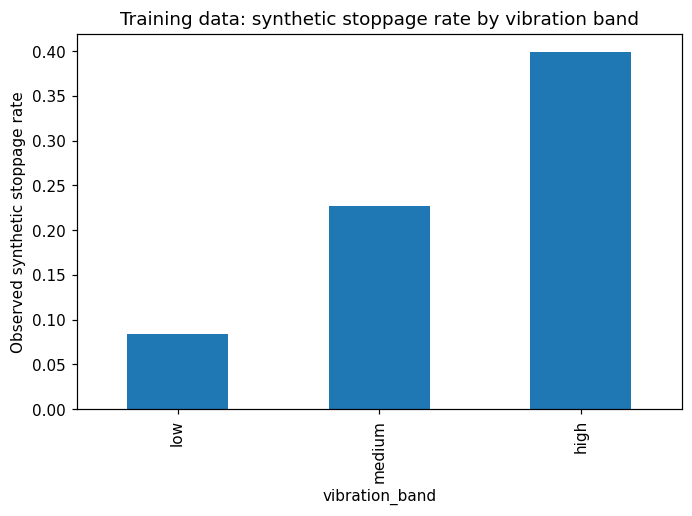

In [5]:
analysis = train_df.assign(vibration_band=pd.cut(train_df["vibration_mm_s"],
    bins=[0,4,8,12], labels=["low","medium","high"]))
summary = analysis.groupby("vibration_band", observed=True).agg(
    conveyors=(TARGET,"size"), stoppage_rate=(TARGET,"mean"),
    average_temperature=("bearing_temperature_c","mean"))
print(summary.round(3).to_string())
print("Training snapshots above 85 C (illustrative filter, not a safety limit):")
print(train_df.loc[train_df["bearing_temperature_c"] > 85,
    [GROUP,"bearing_temperature_c","vibration_mm_s",TARGET]].head().round(2).to_string(index=False))
summary["stoppage_rate"].plot.bar(title="Training data: synthetic stoppage rate by vibration band")
plt.ylabel("Observed synthetic stoppage rate")
plt.tight_layout()

## 7. Training-only preprocessing and model / Подготовка и обучение
Fit the median imputer exclusively on training records inside a Pipeline. Fixed model settings; no test-set tuning.

In [6]:
model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("forest", RandomForestClassifier(n_estimators=160, min_samples_leaf=14, random_state=23, n_jobs=1))])
baseline = DummyClassifier(strategy="prior")
model.fit(X_train, y_train)
baseline.fit(X_train, y_train)
print("Training complete; fitted features:", FEATURES)

Training complete; fitted features: ['vibration_mm_s', 'bearing_temperature_c', 'motor_current_a', 'belt_speed_m_s', 'throughput_tph', 'hours_since_maintenance']


## 8. Held-out evaluation / Проверка на отложенных данных
Compare with a simple baseline. Synthetic test performance does not establish real-site accuracy.

              model  average_precision  Brier_score
      Random forest             0.6491       0.1338
Training prevalence             0.2500       0.1875
ROC AUC: 0.8409
Precision at 0.50: 0.7077
Recall at 0.50: 0.3833


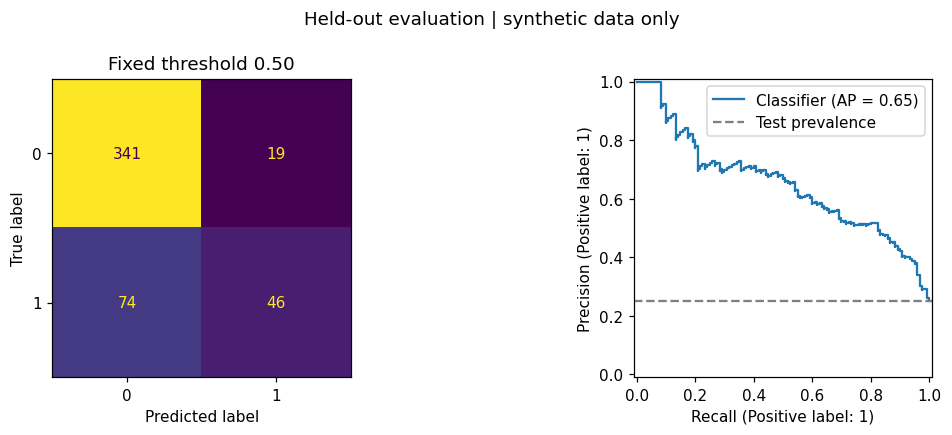

In [7]:
probability = model.predict_proba(X_test)[:,1]
baseline_probability = baseline.predict_proba(X_test)[:,1]
prediction = probability >= 0.50  # Fixed before viewing test outcomes.
comparison = pd.DataFrame({"model":["Random forest","Training prevalence"],
    "average_precision":[average_precision_score(y_test,probability),
                         average_precision_score(y_test,baseline_probability)],
    "Brier_score":[brier_score_loss(y_test,probability),
                   brier_score_loss(y_test,baseline_probability)]})
print(comparison.round(4).to_string(index=False))
print("ROC AUC:", round(roc_auc_score(y_test,probability),4))
print("Precision at 0.50:", round(precision_score(y_test,prediction,zero_division=0),4))
print("Recall at 0.50:", round(recall_score(y_test,prediction,zero_division=0),4))
assert np.isfinite(probability).all()
fig, axes = plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,prediction,ax=axes[0],colorbar=False)
axes[0].set_title("Fixed threshold 0.50")
PrecisionRecallDisplay.from_predictions(y_test,probability,ax=axes[1])
axes[1].axhline(y_test.mean(),ls="--",color="grey",label="Test prevalence")
axes[1].legend()
fig.suptitle("Held-out evaluation | synthetic data only")
plt.tight_layout()

## 9. Model interpretation / Интерпретация
Permutation importance measures score deterioration after shuffling an input. It is not evidence of causality; correlated features can share importance.

                feature  importance    std
         vibration_mm_s      0.2248 0.0272
  bearing_temperature_c      0.1314 0.0333
hours_since_maintenance      0.0542 0.0038
        motor_current_a      0.0416 0.0166
         throughput_tph      0.0235 0.0074
         belt_speed_m_s     -0.0039 0.0031


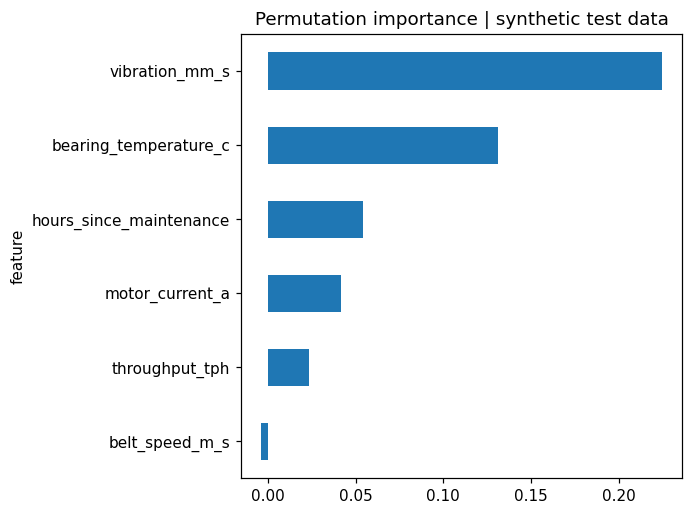

In [8]:
importance = permutation_importance(model, X_test, y_test,
    scoring='average_precision', n_repeats=5, random_state=29)
importance_df = pd.DataFrame({"feature": FEATURES,
    "importance": importance.importances_mean,
    "std": importance.importances_std}).sort_values("importance", ascending=False)
print(importance_df.round(4).to_string(index=False))
importance_df.sort_values("importance").plot.barh(x="feature", y="importance", legend=False)
plt.title("Permutation importance | synthetic test data")
plt.tight_layout()

## 10. Conclusions and next steps / Выводы
- The workflow demonstrates Pandas preparation, scikit-learn preprocessing, training and baseline comparison.
- All findings depend on the explicitly imposed synthetic mechanism; no measured business savings are claimed.
- This single group holdout is not forward-time validation. A real pilot needs approved historical records, availability checks, temporal evaluation, calibration review and monitoring.
- Engineers and planners own operational decisions. The model cannot operate or stop equipment.

Практика: объясните целевую переменную, зачем отделять проверочные данные и чем модель лучше базового варианта. Затем измените один параметр и сравните результаты, не выбирая лучший вариант по тестовой выборке.
